<a href="https://colab.research.google.com/github/jfaraudo/Softmatter_simulation_Introductory_course/blob/main/1_What_is_Soft_Matter/Softmatter_energy_scales_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Energy confluence at the nanoscale
The objective of this Notebook is to illustrate the confluence of multiple energy scales for different physical effects at the nanoscale and how this naturally leads to softmatter, and thermal and quantum fluctuations.
For physical constants always check CODATA standard values, for example here: https://physics.nist.gov/

In [ ]:
#Import python numerical libraries
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Define physical constants and interesting characteristic values
kB=1.380649e-23 #Boltzmann constant kB in Joule
kB_eV=8.617333262e-5 # KB in eV see https://physics.nist.gov/cgi-bin/cuu/Value?kev
qe=1.602176634E-19 #elementary charge in C
me=9.1093837139E-31 #electron mass in Kg
h=6.62607015E-34 #Planck constant J/s
ep0=8.8541878188E-12 #hVacuum electric permittivity ttps://physics.nist.gov/cgi-bin/cuu/Value?ep0
Na=6.02214076E23 #Avogadro Number

### Thermal energy at ambient temperature in different units and energy scales

In [ ]:
T=300 #Temperature in Kelvin
TE=kB*T #Thermal energy in SI
TE_eV=kB_eV*T #Thermal Energy in eV
print(f"Thermal Energy at {T}K:")
print(f"{TE:.2e} J = {TE*Na/1000:.2e} kJ/mol ={TE_eV:.2e} eV")

Thermal Energy at 300K:
4.14e-21 J = 2.49e+00 kJ/mol =2.59e-02 eV


In [ ]:
Hb=20000/Na #Typical energy of a molecular hydrogen bond: 20 kJ/mol
Scv=150000/Na #Typical Energy of a single covalent bond: 150 kJ/mol
print(f"Some energies compared with thermal energy:")
print(f"Typical hydrogen bond: {Hb/TE:.1f}kT")
print(f"Typical covalent bond: {Scv/TE:.1f}kT")

Some energies compared with thermal energy:
Typical hydrogen bond: 8.0kT
Typical covalent bond: 60.1kT


### Bending energy for a rod
Assuming a cylinder of length $L$ bended to make a semi-circle of radius $L=\pi R$ of a material with Young modulus $Y$, the bending energy is:
$$
E_b=\frac{Y\pi^3R^4}{8L}=\frac{Y\pi^3R^3}{8\alpha}
$$
(where $\alpha=L/R$ is the aspect ratio).

In [ ]:
#Numerical example of a rod as a function of radius (fixed aspect ratio)
Y=0.1E9 # Young Modulus 0.1 GPa - 1 GPa
rc=1E-9
alpha=100
Eb_example=Y*(np.pi**3)*(rc**3.0)/(8*alpha)
print(Eb_example/TE)

0.9357397825316157


In [ ]:
# logarithmic spacing https://#www.geeksforgeeks.org/python/how-to-create-a-list-of-uniformly-spaced-numbers-using-a-logarithmic-scale-with-python/
x=np.geomspace(0.001, 10000, 10, endpoint = True)
print(x)

[1.00000000e-03 5.99484250e-03 3.59381366e-02 2.15443469e-01
 1.29154967e+00 7.74263683e+00 4.64158883e+01 2.78255940e+02
 1.66810054e+03 1.00000000e+04]


In [ ]:
#Example for a nanorod with variable radius (aspect ratio 100)
#x = np.arange(0.01,10000,0.01)
Eb = Eb_example*(x**3.0)/TE
print(x,Eb)

[1.00000000e-03 5.99484250e-03 3.59381366e-02 2.15443469e-01
 1.29154967e+00 7.74263683e+00 4.64158883e+01 2.78255940e+02
 1.66810054e+03 1.00000000e+04] [9.35739783e-10 2.01599025e-07 4.34331933e-05 9.35739783e-03
 2.01599025e+00 4.34331933e+02 9.35739783e+04 2.01599025e+07
 4.34331933e+09 9.35739783e+11]


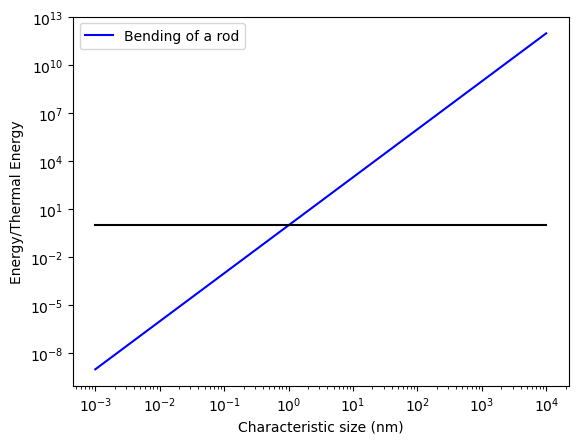

In [ ]:
plt.plot(x,Eb,label='Bending of a rod',color="blue")
plt.plot(x,np.ones(len(x)),color="black")
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Characteristic size (nm)')
plt.ylabel('Energy/Thermal Energy')
plt.legend()
plt.show()

### Ionic interaction in water
Binding electrostatic energy (Coulomb) between two oppositely charged spheres (ions, nanoparticles,...) of diameter $d$ in water ($\epsilon_r=80$):
$$
E_{ionic}=\frac{e^2}{4\pi\epsilon_0\epsilon_rd}
$$

In [ ]:
#Example for the case of d=1 nm
d=1E-9
epsr=80
Eion_ex=(qe**2)/(4*np.pi*ep0*epsr*d*TE)
print(Eion_ex)

0.6962539449377173


In [ ]:
#Eariable diameter
Eion = Eion_ex/x
#print(x,Eb)

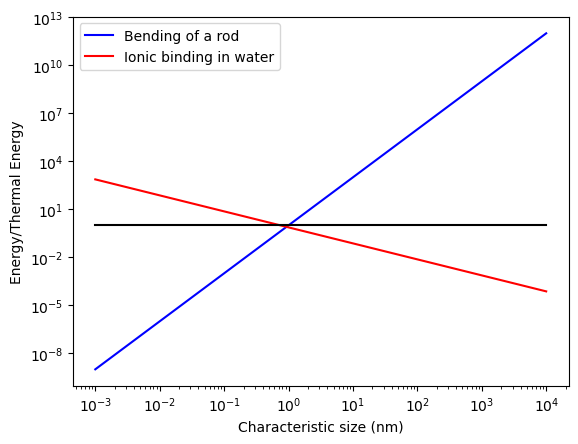

In [ ]:
plt.plot(x,Eb,label='Bending of a rod',color="blue")
plt.plot(x,Eion,label='Ionic binding in water',color="red")
plt.plot(x,np.ones(len(x)),color="black")
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Characteristic size (nm)')
plt.ylabel('Energy/Thermal Energy')
plt.legend()
plt.show()

### Energy of one electron in a nanometric box

The quantum mechanical energy for a particle in a box is given by:
$$
E=\frac{n^2h^2}{8mL^2}
$$
see for example
https://chem.libretexts.org/Courses/Pacific_Union_College/Quantum_Chemistry/03%3A_The_Schrodinger_Equation_and_a_Particle_in_a_Box/3.05%3A_The_Energy_of_a_Particle_in_a_Box_is_Quantized

So for an electron at the ground state in a nanometric box it is given by:

In [ ]:
L=1E-9 #one nanometer
Ebox_ex=h**2/(8*me*qe*L**2) #Energy in eV
print("Energy in eV=",Ebox_ex)
print("Energy compared with kT=",Ebox_ex/TE_eV)

Energy in eV= 0.3760301621048726
Energy compared with kT= 14.54549610156308


In [ ]:
Ebox = (Ebox_ex/TE_eV)/(x**2.0)
#print(x,y)

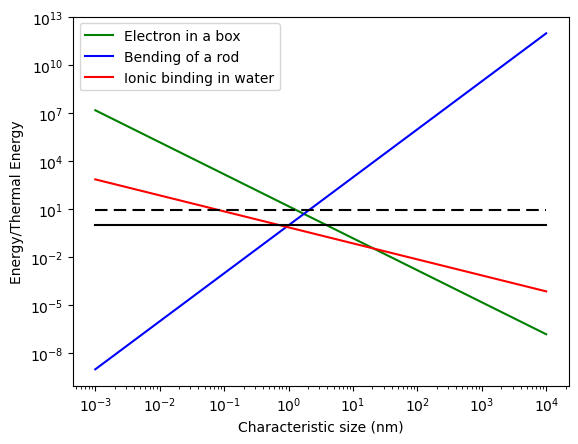

In [ ]:
plt.plot(x,Ebox, label='Electron in a box',color="green")
plt.plot(x,Eb,label='Bending of a rod',color="blue")
plt.plot(x,Eion,label='Ionic binding in water',color="red")
plt.plot(x,np.ones(len(x)),color="black")
plt.plot(x,(Hb/TE)*np.ones(len(x)),color="black",dashes=[6,3])
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Characteristic size (nm)')
plt.ylabel('Energy/Thermal Energy')
plt.legend()
plt.show()